In [ ]:
import pandas as pd

file_url = "https://drive.google.com/uc?id=1V__f51786TveeztJfIJf9FqNcEGUCR-t"

df = pd.read_csv(file_url)


# Module 1

Tingkat Pembatalan (is_ canceled)

In [ ]:
total_reservasi = df.shape[0]
total_batal = df['is_canceled'].sum()
persentase_batal = (total_batal / total_reservasi) * 100
print(f'Total Reservasi: {total_reservasi}')
print(f'Total Reservasi Dibatalkan: {total_batal}')
print(f'Persentase Reservasi Dibatalkan: {persentase_batal:.2f}%')

Total Reservasi: 119390
Total Reservasi Dibatalkan: 44224
Persentase Reservasi Dibatalkan: 37.04%


Variabilitas dalam (lead_time)

In [ ]:
lead_time_stats = df['lead_time'].describe()
print(lead_time_stats)

count    119390.000000
mean         72.880476
std         101.382205
min           0.000000
25%           0.000000
50%          24.000000
75%         114.000000
max         737.000000
Name: lead_time, dtype: float64


Efektivitas Penanganan Permintaan Khusus (total_of_special_requests)

In [ ]:
special_requests_stats = df['total_of_special_requests'].value_counts().sort_index()
print("Distribusi Permintaan Khusus:")
print(special_requests_stats)
average_special_requests = df['total_of_special_requests'].mean()
print(f"Rata-rata jumlah permintaan khusus: {average_special_requests:.2f}")

Distribusi Permintaan Khusus:
total_of_special_requests
0.0    49114
1.0    23356
2.0     9098
3.0     1748
4.0      231
5.0       26
Name: count, dtype: int64
Rata-rata jumlah permintaan khusus: 0.57


Proses Pembayaran yang Tidak Efisien

In [ ]:
# Analisis kegagalan pembayaran
failed_payment_count = df[df['reservation_status'] != 'Check-Out'].shape[0]
print(f"Jumlah reservasi yang tidak berhasil (tidak berstatus 'Check-Out'): {failed_payment_count}")

# Rata-rata ADR (tarif harian) untuk reservasi yang berhasil dan gagal
adr_successful = df[df['reservation_status'] == 'Check-Out']['adr'].mean()
adr_failed = df[df['reservation_status'] != 'Check-Out']['adr'].mean()

print(f"Rata-rata ADR untuk reservasi berhasil: {adr_successful:.2f}")
print(f"Rata-rata ADR untuk reservasi gagal: {adr_failed:.2f}")


Jumlah reservasi yang tidak berhasil (tidak berstatus 'Check-Out'): 44224
Rata-rata ADR untuk reservasi berhasil: 100.15
Rata-rata ADR untuk reservasi gagal: 105.11


Status Reservasi yang mungkin tidak berstatus Check-out atau canceled

In [ ]:
# Analisis komunikasi selama check-in dan check-out
reservation_status_counts = df['reservation_status'].value_counts()
print("Distribusi Status Reservasi:")
print(reservation_status_counts)

# Persentase reservasi dengan status bermasalah
canceled_percentage = (reservation_status_counts['Canceled'] / df.shape[0]) * 100
no_show_percentage = (reservation_status_counts.get('No-Show', 0) / df.shape[0]) * 100  # Cek jika 'No-Show' ada dalam data

print(f"Persentase reservasi dibatalkan: {canceled_percentage:.2f}%")
print(f"Persentase reservasi no-show: {no_show_percentage:.2f}%")


Distribusi Status Reservasi:
reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64
Persentase reservasi dibatalkan: 36.03%
Persentase reservasi no-show: 1.01%


# **Data Preprocessing**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 37 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Unnamed: 0                      119390 non-null  int64  
 1   hotel                           119390 non-null  object 
 2   is_canceled                     119390 non-null  int64  
 3   lead_time                       83573 non-null   float64
 4   arrival_date_year               119390 non-null  int64  
 5   arrival_date_month              119390 non-null  object 
 6   arrival_date_week_number        119390 non-null  int64  
 7   arrival_date_day_of_month       119390 non-null  int64  
 8   stays_in_weekend_nights         83573 non-null   float64
 9   stays_in_week_nights            119390 non-null  int64  
 10  adults                          83573 non-null   float64
 11  children                        119386 non-null  float64
 12  babies          

In [ ]:
df.describe()

,Unnamed: 0,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,83573.000000,119390.000000,119390.000000,119390.000000,83573.000000,119390.000000,83573.000000,119386.000000,...,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,83573.000000,119390.000000,83573.000000
mean,59694.500000,0.370416,104.114965,2016.156554,27.165173,15.798241,0.924366,2.500302,1.855934,0.103890,...,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.985427,0.062518,0.572553
std,34465.068657,0.482918,106.917703,0.707476,13.605138,8.780829,0.995809,1.908286,0.602225,0.398561,...,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,48.140440,0.245291,0.792058
min,0.000000,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,29847.250000,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.670000,0.000000,0.000000
50%,59694.500000,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,95.000000,0.000000,0.000000
75%,89541.750000,1.000000,161.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,119389.000000,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,...,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,510.000000,8.000000,5.000000


In [ ]:
df.columns

Index(['Unnamed: 0', 'hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'name', 'email',
       'phone-number', 'credit_card'],
      dtype='object')

In [ ]:
df.dtypes

,0
Unnamed: 0,int64
hotel,object
is_canceled,int64
lead_time,float64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,float64
stays_in_week_nights,int64


In [ ]:
df = df.drop(columns=['Unnamed: 0'])

In [ ]:
# Menampilkan data awal
print("Data awal:")
pd.set_option('display.max_columns', None)
df.head(10)

Data awal:


,Unnamed: 0,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,0,Resort Hotel,0,342.0,2015,July,27,1,NaN,0,2.0,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0.0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,1,Resort Hotel,0,737.0,2015,July,27,1,0.0,0,2.0,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0.0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,2,Resort Hotel,0,7.0,2015,July,27,1,NaN,1,1.0,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,NaN,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,3,Resort Hotel,0,13.0,2015,July,27,1,0.0,1,1.0,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,NaN,0,NaN,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,4,Resort Hotel,0,NaN,2015,July,27,1,0.0,2,NaN,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,NaN,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498
5,5,Resort Hotel,0,14.0,2015,July,27,1,0.0,2,NaN,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,NaN,0,1.0,Check-Out,2015-07-03,Jasmine Fletcher,JFletcher43@xfinity.com,190-271-6743,************9263
6,6,Resort Hotel,0,NaN,2015,July,27,1,0.0,2,2.0,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,NaN,NaN,0,Transient,107.0,0,NaN,Check-Out,2015-07-03,Dylan Rangel,Rangel.Dylan@comcast.net,420-332-5209,************6994
7,7,Resort Hotel,0,9.0,2015,July,27,1,0.0,2,2.0,0.0,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,303.0,NaN,0,Transient,NaN,0,1.0,Check-Out,2015-07-03,William Velez,Velez_William@mail.com,286-669-4333,************8729
8,8,Resort Hotel,1,NaN,2015,July,27,1,0.0,3,2.0,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,82.0,0,1.0,Canceled,2015-05-06,Steven Murphy,Steven.Murphy54@aol.com,341-726-5787,************3639
9,9,Resort Hotel,1,75.0,2015,July,27,1,NaN,3,2.0,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,D,D,0,No Deposit,15.0,NaN,0,Transient,105.5,0,NaN,Canceled,2015-04-22,Michael Moore,MichaelMoore81@outlook.com,316-648-6176,************9190


Menghapus data duplikat

In [ ]:
df.duplicated().sum()

0

In [ ]:
# 1. Menghapus baris duplikat
df = df.drop_duplicates()
print("\nData setelah menghapus duplikat:")
pd.set_option('display.max_columns', None)
df.head(10)

Mengtasi missing data

In [ ]:
# 2. Mengatasi missing data hanya untuk kolom tertentu

df['children'].fillna(0, inplace=True)  # Mengganti missing 'children' dengan 0
df['country'].fillna('Unknown', inplace=True)  # Mengganti missing 'country' dengan 'Unknown'
df['agent'].fillna(0, inplace=True)  # Mengganti missing 'agent' dengan 0 (tidak ada agent)
df['company'].fillna(0, inplace=True)  # Mengganti missing 'company' dengan 0 (tidak ada company)

df['lead_time'].fillna(0, inplace=True)  # Mengganti missing 'lead_time' dengan 0 (tidak ada lead time)
df['stays_in_weekend_nights'].fillna(0, inplace=True)  # Mengganti missing 'stays_in_weekend_nights' dengan 0 (tidak ada weekend nights)
df['adults'].fillna(0, inplace=True)  # Mengganti missing 'adults' dengan 0 (tidak ada adults)
df['total_of_special_requests'].fillna(0, inplace=True)  # Mengganti missing 'total_of_special_requests' dengan 0 (tidak ada special requests)

In [ ]:
# Mengganti missing values pada kolom 'adr' dengan nilai rata-rata
df['adr'].fillna(df['adr'].mean(), inplace=True)

<ipython-input-8-241eea13b9d2>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['adr'].fillna(df['adr'].mean(), inplace=True)


In [ ]:
print("\nData setelah menangani missing values pada kolom tertentu:")
print(df.isnull().sum())  # Mengecek apakah masih ada missing values


Data setelah menangani missing values pada kolom tertentu:
hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
cust

In [ ]:
pd.set_option('display.max_columns', None)
df.head(10)

,Unnamed: 0,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,0,Resort Hotel,0,342.0,2015,July,27,1,0.0,0,2.0,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0.0,0.0,0,Transient,0.000000,0,0.0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,1,Resort Hotel,0,737.0,2015,July,27,1,0.0,0,2.0,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0.0,0.0,0,Transient,0.000000,0,0.0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,2,Resort Hotel,0,7.0,2015,July,27,1,0.0,1,1.0,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0.0,0.0,0,Transient,75.000000,0,0.0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,3,Resort Hotel,0,13.0,2015,July,27,1,0.0,1,1.0,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,0.0,0,Transient,101.985427,0,0.0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,4,Resort Hotel,0,0.0,2015,July,27,1,0.0,2,0.0,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0.0,0,Transient,98.000000,0,0.0,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498
5,5,Resort Hotel,0,14.0,2015,July,27,1,0.0,2,0.0,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0.0,0,Transient,101.985427,0,1.0,Check-Out,2015-07-03,Jasmine Fletcher,JFletcher43@xfinity.com,190-271-6743,************9263
6,6,Resort Hotel,0,0.0,2015,July,27,1,0.0,2,2.0,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,0.0,0.0,0,Transient,107.000000,0,0.0,Check-Out,2015-07-03,Dylan Rangel,Rangel.Dylan@comcast.net,420-332-5209,************6994
7,7,Resort Hotel,0,9.0,2015,July,27,1,0.0,2,2.0,0.0,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,303.0,0.0,0,Transient,101.985427,0,1.0,Check-Out,2015-07-03,William Velez,Velez_William@mail.com,286-669-4333,************8729
8,8,Resort Hotel,1,0.0,2015,July,27,1,0.0,3,2.0,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0.0,0,Transient,82.000000,0,1.0,Canceled,2015-05-06,Steven Murphy,Steven.Murphy54@aol.com,341-726-5787,************3639
9,9,Resort Hotel,1,75.0,2015,July,27,1,0.0,3,2.0,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,D,D,0,No Deposit,15.0,0.0,0,Transient,105.500000,0,0.0,Canceled,2015-04-22,Michael Moore,MichaelMoore81@outlook.com,316-648-6176,************9190


In [ ]:
df[df['adr']<=0]['adr'].value_counts()

,count
adr,
0.00,1371
-6.38,1


Mengganti nilai mines dengan 0

In [ ]:
# Replace negative ADR values with 0
df['adr'] = df['adr'].apply(lambda x: 0 if x < 0 else x)

In [ ]:
df[df['adr']<=0]['adr'].value_counts()

,count
adr,
0.0,1372


Mengganti Undifined dengan SC , dengan asumsi termasuk orang yang tidak memesan makanan atau Self Centering

In [ ]:
print(df['meal'].value_counts())

meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64


In [ ]:
df['meal'] = df['meal'].map({'Undefined': 'SC', 'BB': 'BB', 'HB': 'HB', 'SC': 'SC', 'FB': 'FB'});
df['meal'].value_counts(ascending=False)
# Mengganti value Undefined ke SC karena bisa dikatakan undefined termasuk Self Centering

,count
meal,
BB,92310
HB,14463
SC,11819
FB,798


**MODUL 3**

In [ ]:
import sqlite3
from sqlalchemy import create_engine

engine = create_engine('sqlite://', echo=False)
df.to_sql('hotel_bookings_clean', con=engine, index=False, if_exists='replace')

pd.read_sql("SELECT * FROM hotel_bookings_clean LIMIT 5;", con=engine)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342.0,2015,July,27,1,0.0,0,2.0,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0.0,0.0,0,Transient,0.000000,0,0.0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737.0,2015,July,27,1,0.0,0,2.0,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0.0,0.0,0,Transient,0.000000,0,0.0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7.0,2015,July,27,1,0.0,1,1.0,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0.0,0.0,0,Transient,75.000000,0,0.0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13.0,2015,July,27,1,0.0,1,1.0,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,0.0,0,Transient,101.985427,0,0.0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,0.0,2015,July,27,1,0.0,2,0.0,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0.0,0,Transient,98.000000,0,0.0,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498
5,Resort Hotel,0,14.0,2015,July,27,1,0.0,2,0.0,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0.0,0,Transient,101.985427,0,1.0,Check-Out,2015-07-03,Jasmine Fletcher,JFletcher43@xfinity.com,190-271-6743,************9263
6,Resort Hotel,0,0.0,2015,July,27,1,0.0,2,2.0,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,0.0,0.0,0,Transient,107.000000,0,0.0,Check-Out,2015-07-03,Dylan Rangel,Rangel.Dylan@comcast.net,420-332-5209,************6994
7,Resort Hotel,0,9.0,2015,July,27,1,0.0,2,2.0,0.0,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,303.0,0.0,0,Transient,101.985427,0,1.0,Check-Out,2015-07-03,William Velez,Velez_William@mail.com,286-669-4333,************8729
8,Resort Hotel,1,0.0,2015,July,27,1,0.0,3,2.0,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0.0,0,Transient,82.000000,0,1.0,Canceled,2015-05-06,Steven Murphy,Steven.Murphy54@aol.com,341-726-5787,************3639
9,Resort Hotel,1,75.0,2015,July,27,1,0.0,3,2.0,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,D,D,0,No Deposit,15.0,0.0,0,Transient,105.500000,0,0.0,Canceled,2015-04-22,Michael Moore,MichaelMoore81@outlook.com,316-648-6176,************9190


# **MODUL 3**

 Task 1: Menghitung tingkat pembatalan reservasi untuk setiap jenis hotel (hotel) berdasarkan tahun
(arrival_date_year).

In [ ]:
import sqlite3
from sqlalchemy import create_engine

engine = create_engine('sqlite://', echo=False)
df.to_sql('hotel_bookings_clean', con=engine, index=False, if_exists='replace')

query_1 = """
SELECT
    hotel,
    arrival_date_year,
    ROUND(SUM(is_canceled) * 100.0 / COUNT(*), 2) AS cancellation_rate
FROM
    hotel_bookings_clean
GROUP BY
    hotel,
    arrival_date_year;
"""
result_1 = pd.read_sql(query_1, con=engine)
result_1

,hotel,arrival_date_year,cancellation_rate
0,City Hotel,2015,43.88
1,City Hotel,2016,40.40
2,City Hotel,2017,42.50
3,Resort Hotel,2015,25.72
4,Resort Hotel,2016,26.55
5,Resort Hotel,2017,30.76


Task 2: Menghitung rata-rata waktu tunggu sebelum check-in (lead_time) untuk setiap kelompok jumlah permintaan
khusus (total_of_special_requests), tetapi hanya untuk reservasi yang memiliki lead time di atas ratarata (yaitu, hanya hitung rata-rata lead time untuk reservasi yang lead time-nya lebih tinggi dari rata-rata
keseluruhan) (5 pts)

In [ ]:
query_2 = """
WITH AboveAverageLeadTime AS (
    SELECT *
    FROM hotel_bookings_clean
    WHERE lead_time > (SELECT AVG(lead_time) FROM hotel_bookings_clean)
)
SELECT
    total_of_special_requests,
    AVG(lead_time) AS average_lead_time
FROM
    AboveAverageLeadTime
GROUP BY
    total_of_special_requests;
"""
result_2 = pd.read_sql(query_2, con=engine)
result_2

,total_of_special_requests,average_lead_time
0,0.0,193.783906
1,1.0,172.724630
2,2.0,166.564915
3,3.0,163.263866
4,4.0,182.831325
5,5.0,171.545455


Task 3: Temukan tanggal reservasi (reservation_status_date) dengan pendapatan tertinggi, yang dihitung
berdasarkan rata-rata tarif harian (adr) dari reservasi yang telah selesai (status Check-Out). Namun,
hanya sertakan reservasi yang memiliki jumlah permintaan khusus lebih dari 2. Selain itu, pendapatan tertinggi
harus dihitung berdasarkan rata-rata pendapatan per reservasi untuk setiap tanggal.

In [ ]:
query_3 = """
SELECT
    reservation_status_date,
    SUM(adr) AS total_revenue
FROM
    hotel_bookings_clean
WHERE
    reservation_status = 'Check-Out'
    AND total_of_special_requests > 2
GROUP BY
    reservation_status_date
ORDER BY
    total_revenue DESC
LIMIT 1;
"""
result_3 = pd.read_sql(query_3, con=engine)
result_3

,reservation_status_date,total_revenue
0,2017-08-17,3064.801707


Task 4: Melakukan analisis untuk melihat apakah ada hubungan antara lead time (lead_time) dan keberhasilan
pembayaran (diukur dari nilai adr). Gunakan CTE untuk mengelompokkan data berdasarkan rentang lead time
dan hitung rata-rata nilai adr untuk setiap kelompok.

In [ ]:
query_4 = """
WITH LeadTimeCTE AS (
    SELECT
        CASE
            WHEN lead_time BETWEEN 0 AND 30 THEN '0-30'
            WHEN lead_time BETWEEN 31 AND 60 THEN '31-60'
            WHEN lead_time BETWEEN 61 AND 90 THEN '61-90'
            ELSE '91+'
        END AS lead_time_range,
        adr
    FROM hotel_bookings_clean
)
SELECT
    lead_time_range,
    AVG(adr) AS average_adr
FROM
    LeadTimeCTE
GROUP BY
    lead_time_range;
"""
result_4 = pd.read_sql(query_4, con=engine)
result_4

,lead_time_range,average_adr
0,0-30,101.175599
1,31-60,105.397648
2,61-90,105.168222
3,91+,101.491320


# **MODUL 4**

Task 1: Bagaimana rasio antara lead_time dengan jumlah hari reservasi dibatalkan (is_canceled == 1)

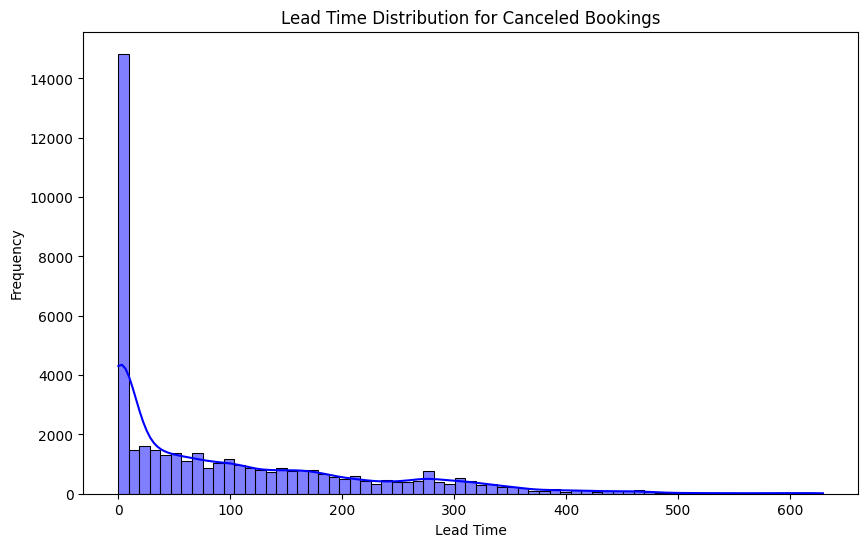

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
# Lead time for canceled bookings
canceled_lead_time = df[df['is_canceled'] == 1]['lead_time']

# Plot the distribution of lead time for canceled bookings
plt.figure(figsize=(10, 6))
sns.histplot(canceled_lead_time, kde=True, color='blue')
plt.title('Lead Time Distribution for Canceled Bookings')
plt.xlabel('Lead Time')
plt.ylabel('Frequency')
plt.show()

Task 2: Apakah ada perbedaan pola pendapatan antara Resort Hotel dan City Hotel selama beberapa bulan
tertentu?

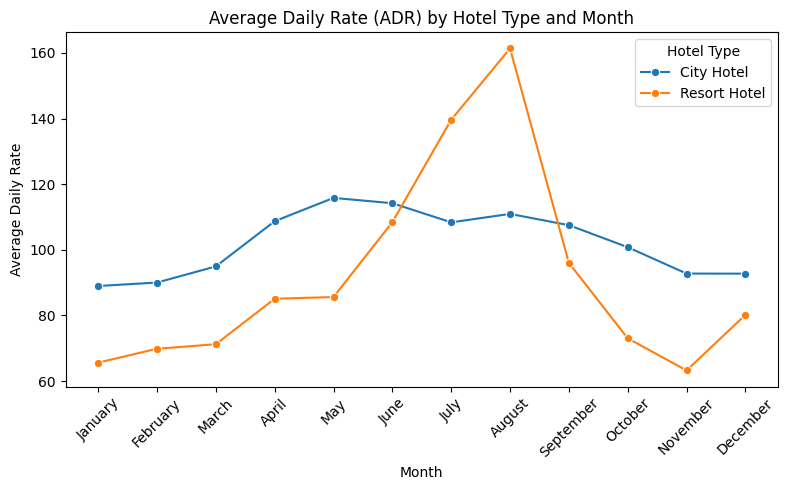

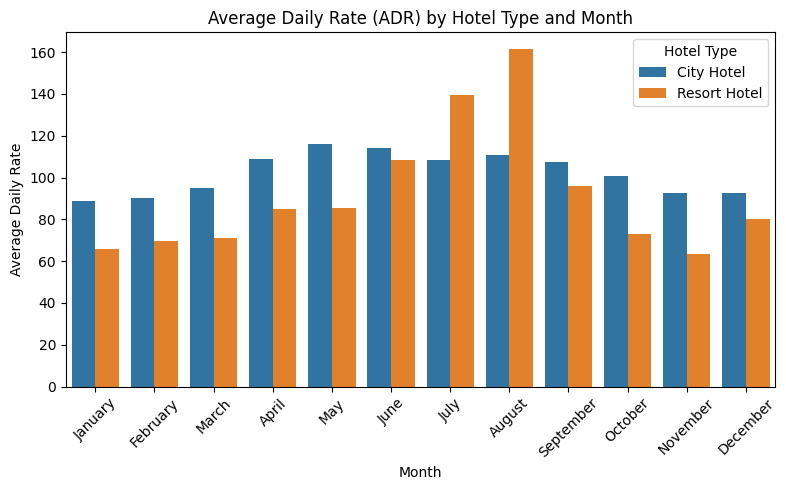

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Group data by hotel type and month, then calculate the average ADR
by_month = df.groupby(['hotel', 'arrival_date_month'])['adr'].mean().reset_index()

# Reorder months for better visualization
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
by_month['arrival_date_month'] = pd.Categorical(by_month['arrival_date_month'], categories=month_order, ordered=True)
adr_by_hotel_month = by_month.sort_values('arrival_date_month')


# Create the line plot
plt.figure(figsize=(8, 5))
sns.lineplot(x='arrival_date_month', y='adr', hue='hotel', data = adr_by_hotel_month, marker='o')
plt.title('Average Daily Rate (ADR) by Hotel Type and Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Rate')
plt.xticks(rotation=45)
plt.legend(title='Hotel Type')
plt.tight_layout()
plt.show()
print("\n")

# Create the bar plot
plt.figure(figsize=(8, 5))
sns.barplot(x='arrival_date_month', y='adr', hue='hotel', data = adr_by_hotel_month)
plt.title('Average Daily Rate (ADR) by Hotel Type and Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Rate')
plt.xticks(rotation=45)
plt.legend(title='Hotel Type')
plt.tight_layout()


Task 3: Turis dari negara mana sajakah yang sering melakukan cancelling reservation baik untuk Resort
Hotel maupun City Hotel

Countries with the Most Canceled Reservations:
    country  is_canceled
97      PRT        27519
41      GBR         2453
33      ESP         2177
38      FRA         1934
60      ITA         1333
27      DEU         1218
56      IRL          832
16      BRA          830
119     USA          501
9       BEL          474




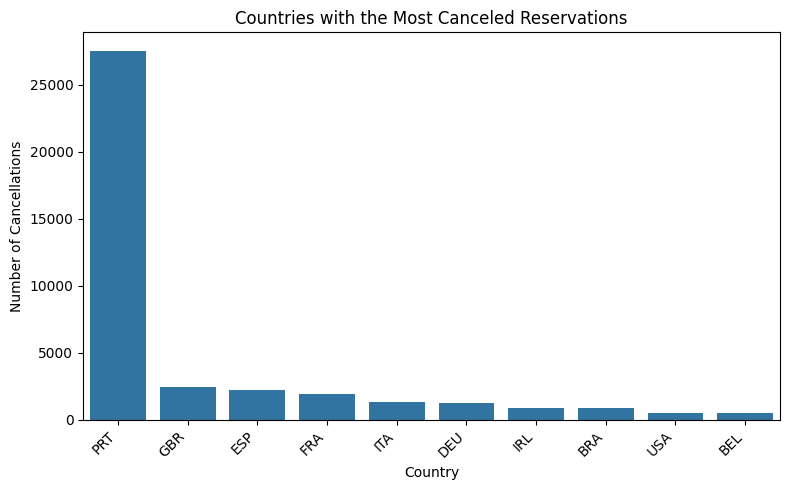

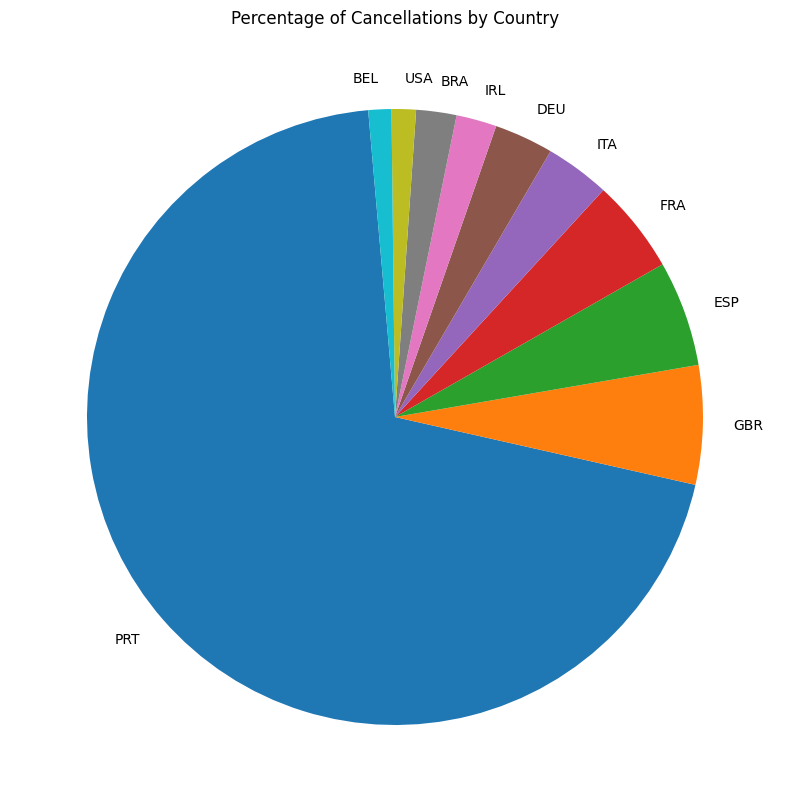

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Group data by country and calculate the number of canceled reservations
canceled_by_country = df[df['is_canceled'] == 1].groupby('country')['is_canceled'].count().reset_index()

# Sort the countries by the number of canceled reservations in descending order
canceled_by_country = canceled_by_country.sort_values('is_canceled', ascending=False)

# Display the top 10 countries with the most cancellations
print('Countries with the Most Canceled Reservations:')
print(canceled_by_country.head(10))
print("\n")

# Create a bar plot to visualize the top 10 countries with the most cancellations
plt.figure(figsize=(8, 5))
sns.barplot(x='country', y='is_canceled', data = canceled_by_country.head(10))
plt.xlabel('Country')
plt.ylabel('Number of Cancellations')
plt.title('Countries with the Most Canceled Reservations')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
print("\n")

# Create pie plot
plt.figure(figsize=(10, 10))
plt.pie(canceled_by_country['is_canceled'].head(10), labels=canceled_by_country['country'].head(10), startangle=95)
plt.title('Percentage of Cancellations by Country')
plt.show()

Task 4: Bagaimana perilaku pemesanan Last-Minute yang terjadi?

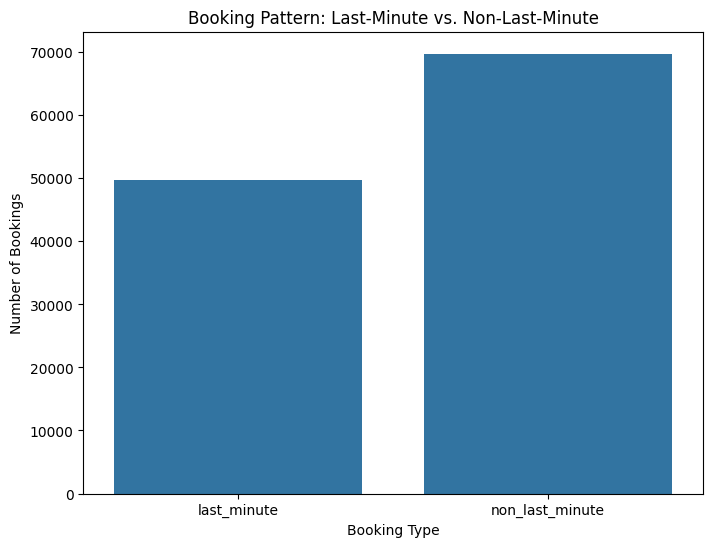

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Defines the last minute threshold
last_minute_threshold = 7

# Create a new column 'booking_type' to categorize bookings
df['booking_type'] = df['lead_time'].apply(lambda x: 'last_minute' if x <= last_minute_threshold else 'non_last_minute')

# Group data by booking type and count occurrences
booking_counts = df.groupby('booking_type')['booking_type'].count().reset_index(name='counts')

# Create the bar plot
plt.figure(figsize=(8, 6))
sns.barplot(x='booking_type', y='counts', data=booking_counts)
plt.title('Booking Pattern: Last-Minute vs. Non-Last-Minute')
plt.xlabel('Booking Type')
plt.ylabel('Number of Bookings')
plt.show()

# **MODUL 5**

City Hotel ADR: 104.41
Resort Hotel ADR: 97.18
T-statistic: 29.431
P-value: 0.00000
Reject the null hypothesis. The average ADR is different for City Hotel and Resort Hotel.




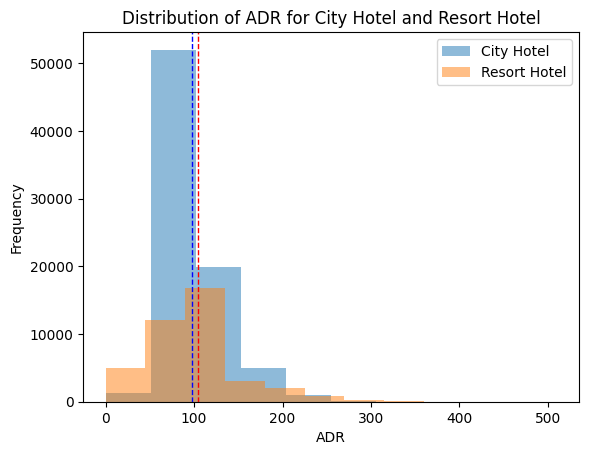

In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt

# Split the data into two groups based on hotel type
city_hotel_adr = df[df['hotel'] == 'City Hotel']['adr']
resort_hotel_adr = df[df['hotel'] == 'Resort Hotel']['adr']

# Calculate the average adr
avg_city_adr = city_hotel_adr.mean()
avg_resort_adr = resort_hotel_adr.mean()

# Perform an independent samples t-test
t_statistic, p_value = stats.ttest_ind(city_hotel_adr, resort_hotel_adr)

# Define the significance level
alpha = 0.05

# Print the results
print(f'City Hotel ADR: {avg_city_adr:.2f}')
print(f'Resort Hotel ADR: {avg_resort_adr:.2f}')
print(f"T-statistic: {t_statistic:.3f}")
print(f"P-value: {p_value:.5f}")

# Determine whether to reject or fail to reject the null hypothesis
if p_value < alpha:
    print("Reject the null hypothesis. The average ADR is different for City Hotel and Resort Hotel.")
else:
    print("Fail to reject the null hypothesis. There is no significant difference in average ADR between City Hotel and Resort Hotel.")

# Plotting the data
plt.hist(city_hotel_adr, alpha=0.5, label='City Hotel')
plt.hist(resort_hotel_adr, alpha=0.5, label='Resort Hotel')
plt.axvline(avg_city_adr, color='r', linestyle='dashed', linewidth=1)
plt.axvline(avg_resort_adr, color='b', linestyle='dashed', linewidth=1)
print('\n')
plt.xlabel('ADR')
plt.ylabel('Frequency')
plt.title('Distribution of ADR for City Hotel and Resort Hotel')
plt.legend(loc='upper right')
plt.show()